# [Bonus Tasks](svm_segm.ipynb)

In [115]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [116]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [117]:
patch_sizes = (32, 32)

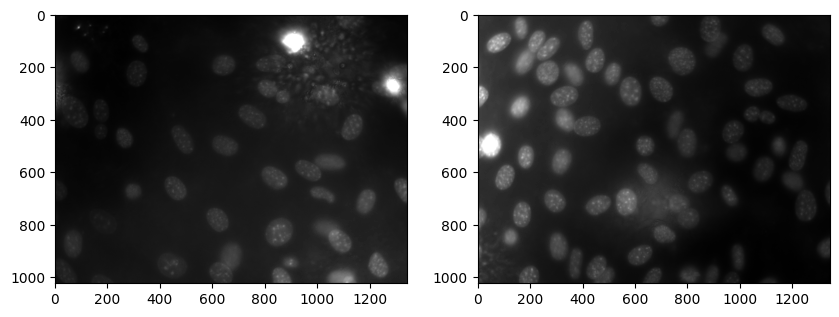

In [118]:
dna_33 = plt.imread("data/NIH3T3/im/dna-33.png")
dna_44 = plt.imread("data/NIH3T3/im/dna-44.png")
plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(dna_33, "gray")
plt.subplot(1, 2, 2)
plt.imshow(dna_44, "gray")

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [119]:
int(((dna_33.shape[1])/patch_sizes[0]) * ((dna_33.shape[0])/patch_sizes[0]))

1344

In [120]:
def create_data_matrix(img, patch_sizes) :
    X = np.zeros((int(((dna_33.shape[1])/patch_sizes[0]) * ((dna_33.shape[0])/patch_sizes[0])), int(patch_sizes[0]**2)))
    blocks = skimage.util.view_as_blocks(img, block_shape = patch_sizes)
    for x in range(blocks.shape[0]) :
        for y in range(blocks.shape[1]) :
            X[int((x*blocks.shape[1])+y),:] = blocks[x,y].flatten()
    return X


**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [121]:
def create_gt_labels_vector(gt, patch_sizes) :
    V = np.zeros((int(((dna_33.shape[1])/patch_sizes[0]) * ((dna_33.shape[0])/patch_sizes[0])), 1))
    blocks = skimage.util.view_as_blocks(gt, block_shape = patch_sizes)
    for x in range(blocks.shape[0]) :
        for y in range(blocks.shape[1]) :
            if (sum(blocks[x,y].flatten()) / blocks[x,y].flatten().shape) > 0.5 :
                V[int((x*blocks.shape[1])+y)] = 1
            elif (sum(blocks[x,y].flatten()) / blocks[x,y].flatten().shape) == 0 :
                V[int((x*blocks.shape[1])+y)] = -1
            else :
                V[int((x*blocks.shape[1])+y)] = 0
    return V

**[Task 1.3.]()** Create the SVM classifier:

In [122]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [123]:
X_dna_33 = create_data_matrix(dna_33, patch_sizes)
X_dna_44 = create_data_matrix(dna_44, patch_sizes)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [124]:
gt_33 = plt.imread("data/NIH3T3/gt/33.png")
gt_44 = plt.imread("data/NIH3T3/gt/44.png")

V_gt_33 = create_gt_labels_vector(gt_33, patch_sizes)
V_gt_44 = create_gt_labels_vector(gt_44, patch_sizes)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [125]:
X_train_stacked = np.concatenate((X_dna_33, X_dna_44))
V_train_stacked = np.concatenate((V_gt_33, V_gt_44))
X_train_stacked = X_train_stacked[V_train_stacked[:, -1] != 0]
V_train_stacked = V_train_stacked[V_train_stacked[:, -1] != 0]

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [126]:
clf.fit(X_train_stacked, V_train_stacked.flatten())

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [127]:
np.zeros(patch_sizes, dtype=bool)

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [128]:
def predict_image(img, patch_sizes):
    X = create_data_matrix(img, patch_sizes)
    F = clf.predict(X)
    background = np.zeros(patch_sizes, dtype=bool)
    foreground = np.ones(patch_sizes, dtype=bool)
    bi_img = np.zeros(img.shape)
    for x in range(int(img.shape[0] / patch_sizes[0])) :
        for y in range(int(img.shape[1] / patch_sizes[1])) :
            if  F[int((x * img.shape[1] / patch_sizes[1]) + y)] == 1 :
                bi_img[int(x * patch_sizes[0]) : int((x+1) * patch_sizes[0]), int(y * patch_sizes[1]) : int((y+1) * patch_sizes[1])] = foreground
            else :
                bi_img[int(x * patch_sizes[0]) : int((x+1) * patch_sizes[0]), int(y * patch_sizes[1]) : int((y+1) * patch_sizes[1])] = background
    return bi_img

Test your implementation:

In [139]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img, patch_sizes)

In [143]:
print(seg.shape == img.shape)
img.dtype

True


dtype('float32')

In [ ]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img, patch_sizes)

plt.figure()
plt.imshow(blend_result(img, seg))

IndexError: arrays used as indices must be of integer (or boolean) type

<Figure size 640x480 with 0 Axes>

**[Task 1.5.]()** Perform batch processing: